# 04 Temporal Feature Engineering

This experiment keeps the baseline split, LightGBM parameters, early stopping, and evaluation unchanged. Its only substantive change is to add five temporal features for the 25 most important original variables. 

All outputs are written separately. The baseline dataset and model remain untouched.


In [16]:
from pathlib import Path

def find_project_root() -> Path:
    """Use the parent of the notebook working directory as the project root."""
    project_root = Path.cwd().resolve().parent
    if not (project_root / 'data').is_dir():
        raise FileNotFoundError(
            "Expected the project data directory one level above the current working directory."
        )
    return project_root

import gc, json, platform, time
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.ipc as ipc
import pyarrow.feather as feather
import pyarrow.parquet as pq
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
print('Python:', platform.python_version())
print('LightGBM:', lgb.__version__)


Python: 3.10.19
LightGBM: 4.7.0


### 1. Resolve project artifacts


In [ ]:
ROOT = find_project_root()
STEP_DIR = ROOT / '04_temporal_features'
BASELINE_DATA = ROOT / '02_aggregation' / 'train_aggregated.parquet'
MONTHLY_DATA = ROOT / 'data' / 'train_data_float16_zstd.feather'
BASELINE_NOTEBOOK = ROOT / '03_baseline' / '03_lightgbm_baseline.ipynb'
BASELINE_IMPORTANCE = ROOT / '03_baseline' / 'baseline_feature_importance.csv'

ORIGINAL_VARIABLE_IMPORTANCE = STEP_DIR / 'original_variable_importance.csv'
V2_DATA = STEP_DIR / 'train_aggregated_temporal.feather'
V2_MODEL = STEP_DIR / 'lightgbm_temporal.txt'
V2_IMPORTANCE = STEP_DIR / 'temporal_feature_importance.csv'
V2_PREDICTIONS = STEP_DIR / 'temporal_validation_predictions.parquet'
V2_METRICS = STEP_DIR / 'temporal_metrics.json'

for path in [BASELINE_DATA, MONTHLY_DATA, BASELINE_NOTEBOOK, BASELINE_IMPORTANCE]:
    assert path.exists(), f'Can not find: {path}'

baseline_metadata = pd.read_parquet(BASELINE_DATA, columns=['customer_ID', 'target'])
baseline_columns = pq.ParquetFile(BASELINE_DATA).schema_arrow.names
print('Baseline aggregated data:', BASELINE_DATA.resolve())
print('Monthly data:', MONTHLY_DATA.resolve())
print('Baseline notebook:', BASELINE_NOTEBOOK.resolve())
print('Baseline importance:', BASELINE_IMPORTANCE.resolve())
print(f'Customers: {len(baseline_metadata):,}')
print(f'Baseline model features: {len(baseline_columns) - 2:,}')
display(baseline_metadata['target'].value_counts().sort_index().to_frame('customer_count'))
display(baseline_metadata['target'].value_counts(normalize=True).sort_index().to_frame('target_rate'))


### 2. Select top 25 source variables by aggregated gain

The baseline has multiple derived columns per source variable. For example, gain from `P_2_mean`, `P_2_std`, `P_2_min`, `P_2_max`, and `P_2_last` is summed back to `P_2`.

Ranking at the source-variable level avoids selecting several variants of the same measurement and focuses the monthly scan on variables with demonstrated baseline signal. 

In [18]:
AGGREGATION_NAMES = ['mean', 'std', 'min', 'max', 'last']

def parse_feature_name(feature):
    for aggregation in AGGREGATION_NAMES:
        suffix = '_' + aggregation
        if feature.endswith(suffix):
            return feature[:-len(suffix)], aggregation
    return feature, 'other'

importance = pd.read_csv(BASELINE_IMPORTANCE).sort_values('gain', ascending=False).reset_index(drop=True)
assert len(importance) == len(baseline_columns) - 2
assert importance['feature'].is_unique
assert np.isclose(importance['gain_percentage'].sum(), 1.0)
importance['feature_rank'] = np.arange(1, len(importance) + 1)
parsed = importance['feature'].map(parse_feature_name)
importance['original_variable'] = [item[0] for item in parsed]
importance['aggregation_type'] = [item[1] for item in parsed]
importance['family'] = importance['original_variable'].str.split('_').str[0]

original_importance = (
    importance.groupby(['original_variable', 'family'], as_index=False)
    .agg(
        total_gain=('gain', 'sum'),
        gain_share=('gain_percentage', 'sum'),
        best_rank=('feature_rank', 'min'),
        aggregations=('aggregation_type', lambda values: ','.join(sorted(set(values)))),
        included_features=('feature', lambda values: ','.join(values)),
    )
    .sort_values(['total_gain', 'original_variable'], ascending=[False, True])
    .reset_index(drop=True)
)
original_importance['original_variable_rank'] = np.arange(1, len(original_importance) + 1)
original_importance.to_csv(ORIGINAL_VARIABLE_IMPORTANCE, index=False)
TOP25 = original_importance.head(25)['original_variable'].tolist()

print('Top 25 original variables:')
display(original_importance.head(25)[[
    'original_variable_rank', 'original_variable', 'family', 'total_gain',
    'gain_share', 'best_rank', 'aggregations'
]])
print(TOP25)


Top 25 original variables:


,original_variable_rank,original_variable,family,total_gain,gain_share,best_rank,aggregations
0,1,P_2,P,2.510121e+06,0.584072,1,"last,max,mean,min,std"
1,2,B_1,B,1.957029e+05,0.045538,3,"last,max,mean,min,std"
2,3,R_1,R,1.067423e+05,0.024838,6,"last,max,mean,min,std"
3,4,D_39,D,8.201419e+04,0.019084,8,"last,max,mean,min,std"
4,5,B_2,B,8.080900e+04,0.018803,4,"last,max,mean,min,std"
5,6,B_9,B,7.386711e+04,0.017188,5,"last,max,mean,min,std"
6,7,S_3,S,6.985433e+04,0.016254,11,"last,max,mean,min,std"
7,8,D_42,D,6.913467e+04,0.016087,12,"last,max,mean,min,std"
8,9,D_44,D,6.437315e+04,0.014979,10,"last,max,mean,min,std"
9,10,B_4,B,5.629135e+04,0.013098,15,"last,max,mean,min,std"


['P_2', 'B_1', 'R_1', 'D_39', 'B_2', 'B_9', 'S_3', 'D_42', 'D_44', 'B_4', 'B_3', 'B_11', 'D_41', 'D_43', 'D_46', 'R_2', 'R_3', 'B_37', 'B_7', 'D_48', 'D_49', 'D_51', 'P_3', 'D_50', 'S_23']


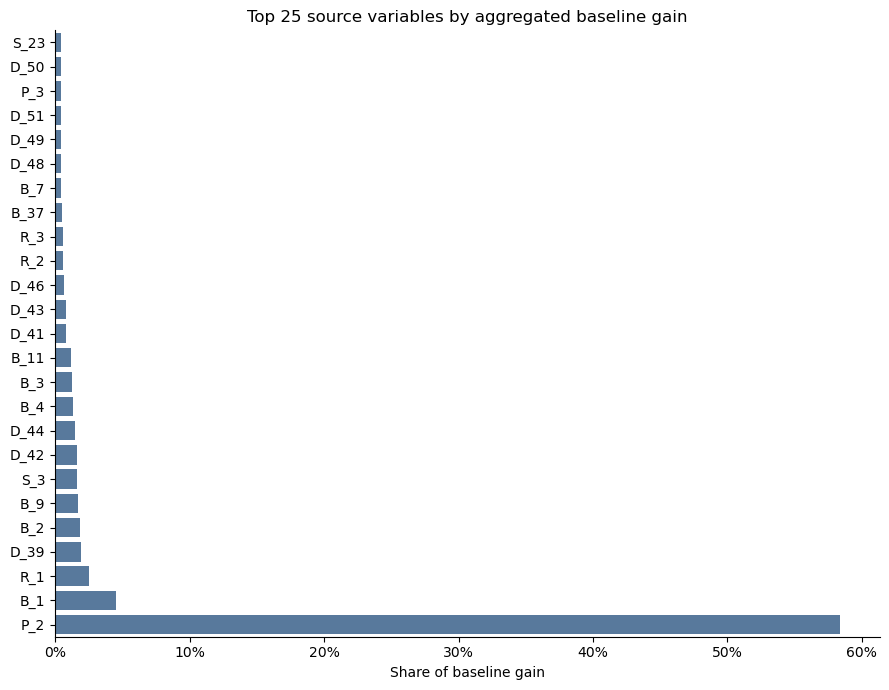

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Source variables selected for temporal engineering
top_source_plot = original_importance.head(25).sort_values('total_gain')
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=top_source_plot, y='original_variable', x='gain_share', color='#4C78A8', ax=ax)
ax.set(title='Top 25 source variables by aggregated baseline gain', xlabel='Share of baseline gain', ylabel='')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
sns.despine()
plt.tight_layout()
plt.show()


### 3. Generate temporal features from monthly history

For each selected variable, the notebook computes:

- `first`: earliest recorded value;
- `last_minus_first`: long-run change;
- `last_minus_mean`: deviation of the current value from historical level;
- `recent_3_mean`: mean of the last three statements;
- `recent_6_mean`: mean of the last six statements.

`first` preserves an actual leading NaN rather than skipping it. 


In [20]:
TEMPORAL_TYPES = ['first', 'last_minus_first', 'last_minus_mean', 'recent_3_mean', 'recent_6_mean']
NEW_TEMPORAL_FEATURES = [f'{variable}_{kind}' for variable in TOP25 for kind in TEMPORAL_TYPES]
sample_customer_ids = set(baseline_metadata['customer_ID'].sample(20, random_state=42).astype('int64'))
audit_monthly_parts = []

def aggregate_temporal(frame):
    grouped = frame.groupby('customer_ID', sort=False, observed=True)
    mean_values = grouped[TOP25].mean()
    first_values = frame.drop_duplicates('customer_ID', keep='first').set_index('customer_ID')[TOP25]
    last_values = frame.drop_duplicates('customer_ID', keep='last').set_index('customer_ID')[TOP25]
    recent_3 = grouped.tail(3).groupby('customer_ID', sort=False)[TOP25].mean()
    recent_6 = grouped.tail(6).groupby('customer_ID', sort=False)[TOP25].mean()

    pieces = []
    pieces.append(first_values.rename(columns=lambda c: f'{c}_first'))
    pieces.append((last_values - first_values).rename(columns=lambda c: f'{c}_last_minus_first'))
    pieces.append((last_values - mean_values).rename(columns=lambda c: f'{c}_last_minus_mean'))
    pieces.append(recent_3.rename(columns=lambda c: f'{c}_recent_3_mean'))
    pieces.append(recent_6.rename(columns=lambda c: f'{c}_recent_6_mean'))
    result = pd.concat(pieces, axis=1).reset_index()
    result[NEW_TEMPORAL_FEATURES] = result[NEW_TEMPORAL_FEATURES].astype('float16')
    return result

def equal_with_nan(left, right, rtol=2e-3, atol=2e-3):
    return np.isclose(np.asarray(left, dtype='float32'), np.asarray(right, dtype='float32'), rtol=rtol, atol=atol, equal_nan=True)


In [ ]:
temporal_parts = []
carry = None
written_customer_ids = set()
started = time.perf_counter()

with pa.memory_map(str(MONTHLY_DATA), 'r') as source:
    reader = ipc.open_file(source)
    selected_names = ['customer_ID', 'S_2', *TOP25]
    selected_indices = [reader.schema.get_field_index(name) for name in selected_names]
    assert min(selected_indices) >= 0

    for batch_index in range(reader.num_record_batches):
        frame = reader.get_batch(batch_index).select(selected_indices).to_pandas()
        if carry is not None:
            frame = pd.concat([carry, frame], ignore_index=True)

        date_ok = frame.groupby('customer_ID', sort=False)['S_2'].apply(
            lambda values: values.is_monotonic_increasing
        ).all()

        last_customer = frame['customer_ID'].iloc[-1]
        carry = frame.loc[frame['customer_ID'] == last_customer].copy()
        complete = frame.loc[frame['customer_ID'] != last_customer].copy()

        if len(complete):
            current_ids = set(complete['customer_ID'].unique())
            assert not current_ids.intersection(written_customer_ids)
            temporal_parts.append(aggregate_temporal(complete))
            audit_monthly_parts.append(complete.loc[complete['customer_ID'].isin(sample_customer_ids)].copy())
            written_customer_ids.update(current_ids)

        if (batch_index + 1) % 10 == 0 or batch_index + 1 == reader.num_record_batches:
            print(f'batch {batch_index + 1}/{reader.num_record_batches}: {len(written_customer_ids):,} customers')

if carry is not None and len(carry):
    temporal_parts.append(aggregate_temporal(carry))
    audit_monthly_parts.append(carry.loc[carry['customer_ID'].isin(sample_customer_ids)].copy())
    written_customer_ids.add(int(carry['customer_ID'].iloc[0]))

temporal = pd.concat(temporal_parts, ignore_index=True)
temporal_generation_seconds = time.perf_counter() - started
print(f'Temporal table: {temporal.shape[0]:,} rows × {temporal.shape[1]:,} columns')
print(f'Generation time: {temporal_generation_seconds:.1f} seconds')


batch 10/56: 82,974 customers
batch 20/56: 165,818 customers
batch 30/56: 248,848 customers
batch 40/56: 331,852 customers
batch 50/56: 414,807 customers
batch 56/56: 458,912 customers
Temporal table: 458,913 rows × 126 columns
Generation time: 43.4 seconds


### 4. Merge temporal features with the baseline table

Temporal features are joined one-to-one by `customer_ID`. The merged table is saved as a new Feather artifact, preserving the baseline feature set and adding only the planned temporal columns.

In [ ]:
baseline = pd.read_parquet(BASELINE_DATA)
assert baseline['customer_ID'].is_unique
assert temporal['customer_ID'].is_unique
assert len(baseline) == len(temporal) == len(written_customer_ids)

merged = baseline.merge(temporal, on='customer_ID', how='left', validate='one_to_one', sort=False)
assert len(merged) == len(baseline)
assert merged['customer_ID'].is_unique
assert not merged[NEW_TEMPORAL_FEATURES].isna().all(axis=1).any()

feather.write_feather(
    pa.Table.from_pandas(merged, preserve_index=False),
    V2_DATA,
    compression='zstd',
    compression_level=6,
    chunksize=65_536,
    version=2,
)
print('Saved:', V2_DATA.resolve())
print(f'File size: {V2_DATA.stat().st_size / 2**30:.2f} GiB')
print(f'New temporal features: {len(NEW_TEMPORAL_FEATURES)}')
print(f'Final model features: {len(baseline_columns) - 2 + len(NEW_TEMPORAL_FEATURES)}')


### 5. Check feature correctness

Checks row count, customer uniqueness, join completeness, and the expected new columns.

In [23]:
audit_monthly = pd.concat(audit_monthly_parts, ignore_index=True).sort_values(['customer_ID', 'S_2'])
audit_temporal = temporal.set_index('customer_ID')
assert audit_monthly['customer_ID'].nunique() == 20

check_rows = []
for customer_id, history in audit_monthly.groupby('customer_ID', sort=False):
    row = audit_temporal.loc[customer_id]
    for variable in TOP25:
        values = history[variable]
        expected_first = values.iloc[0]
        expected_recent_3 = values.tail(3).mean()
        expected_recent_6 = values.tail(6).mean()
        assert equal_with_nan([row[f'{variable}_first']], [expected_first]).all()
        assert equal_with_nan([row[f'{variable}_recent_3_mean']], [expected_recent_3]).all()
        assert equal_with_nan([row[f'{variable}_recent_6_mean']], [expected_recent_6]).all()
    check_rows.append({'customer_ID': customer_id, 'observations': len(history), 'status': 'passed'})

for variable in TOP25:
    assert equal_with_nan(
        merged[f'{variable}_last_minus_first'],
        merged[f'{variable}_last'] - merged[f'{variable}_first'],
    ).all()
    assert equal_with_nan(
        merged[f'{variable}_last_minus_mean'],
        merged[f'{variable}_last'] - merged[f'{variable}_mean'],
    ).all()

display(pd.DataFrame(check_rows))
print('All customer-count, uniqueness, merge, first, recent-3, recent-6 and arithmetic checks passed.')


,customer_ID,observations,status
0,-9158959175944666165,13,passed
1,-9118128419727338713,13,passed
2,-8635165938729149458,13,passed
3,-7490332579644601462,13,passed
4,-2405959144865086720,13,passed
5,-2095553756491726106,13,passed
6,-1881242061365373068,13,passed
7,-1550041511035336225,13,passed
8,-706434273685890312,3,passed
9,280541183639409923,13,passed


All customer-count, uniqueness, merge, first, recent-3, recent-6 and arithmetic checks passed.


### 6. Reproduce the baseline model and train Temporal V2

Both models use the same customer indices, categorical handling, hyperparameters, and early-stopping rule. 

The official AMEX metric is added alongside ROC-AUC. It averages normalized weighted Gini and top-4% default capture, emphasizing both global ranking and performance at the highest-risk end.


In [24]:
def amex_metric(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.int8)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    weights = np.where(y_true == 0, 20.0, 1.0)

    order = np.argsort(-y_pred, kind='mergesort')
    sorted_y = y_true[order]
    sorted_w = weights[order]
    top_mask = np.cumsum(sorted_w) <= 0.04 * sorted_w.sum()
    top_four = (sorted_y[top_mask] * sorted_w[top_mask]).sum() / (y_true * weights).sum()

    def weighted_gini(prediction):
        idx = np.argsort(-prediction, kind='mergesort')
        yy, ww = y_true[idx], weights[idx]
        lorentz = np.cumsum(yy * ww) / np.sum(yy * ww)
        random = np.cumsum(ww) / np.sum(ww)
        return np.sum((lorentz - random) * ww)

    normalized_gini = weighted_gini(y_pred) / weighted_gini(y_true)
    return 0.5 * (normalized_gini + top_four)

def make_model():
    return lgb.LGBMClassifier(
        objective='binary', n_estimators=1500, learning_rate=0.03,
        num_leaves=31, max_depth=-1, min_child_samples=100,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        max_bin=127, random_state=42, n_jobs=4, verbosity=-1,
    )


In [25]:
customer_ids = merged['customer_ID'].copy()
y = merged['target'].astype('int8').copy()
X_all = merged.drop(columns=['customer_ID', 'target']).copy()
X_all['S_2_last'] = (
    pd.to_datetime(X_all['S_2_last']) - pd.Timestamp('2018-03-01')
).dt.days.astype('int16')

ORIGINAL_CATEGORICAL_COLUMNS = [
    'B_30', 'B_38', 'D_114', 'D_116', 'D_117', 'D_120',
    'D_126', 'D_63', 'D_64', 'D_66', 'D_68'
]
CATEGORICAL_FEATURES = [f'{column}_last' for column in ORIGINAL_CATEGORICAL_COLUMNS]
for column in CATEGORICAL_FEATURES:
    X_all[column] = X_all[column].astype('category')

indices = np.arange(len(X_all))
train_indices, valid_indices = train_test_split(
    indices, train_size=0.70, test_size=0.30,
    random_state=42, stratify=y,
)
y_train = y.iloc[train_indices].copy()
y_valid = y.iloc[valid_indices].copy()
valid_customer_ids = customer_ids.iloc[valid_indices].copy()
BASELINE_FEATURES = [column for column in X_all.columns if column not in NEW_TEMPORAL_FEATURES]
assert len(BASELINE_FEATURES) == 897
assert len(X_all.columns) == 1022
print(f'Train: {len(train_indices):,}; validation: {len(valid_indices):,}')
print(f'Baseline features: {len(BASELINE_FEATURES)}; V2 features: {X_all.shape[1]}')


Train: 321,239; validation: 137,674
Baseline features: 897; V2 features: 1022


In [26]:
baseline_model = make_model()
baseline_started = time.perf_counter()
baseline_model.fit(
    X_all.iloc[train_indices][BASELINE_FEATURES], y_train,
    eval_set=[(X_all.iloc[valid_indices][BASELINE_FEATURES], y_valid)],
    eval_metric='auc', categorical_feature=CATEGORICAL_FEATURES,
    callbacks=[lgb.early_stopping(100, verbose=True), lgb.log_evaluation(50)],
)
baseline_training_seconds = time.perf_counter() - baseline_started
baseline_probability = baseline_model.predict_proba(
    X_all.iloc[valid_indices][BASELINE_FEATURES],
    num_iteration=baseline_model.best_iteration_,
)[:, 1]
baseline_result = {
    'roc_auc': roc_auc_score(y_valid, baseline_probability),
    'amex_metric': amex_metric(y_valid, baseline_probability),
    'best_iteration': int(baseline_model.best_iteration_),
    'training_seconds': baseline_training_seconds,
    'feature_count': len(BASELINE_FEATURES),
}
baseline_result


/opt/anaconda3/envs/cs178/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's auc: 0.951214	valid_0's binary_logloss: 0.289477
[100]	valid_0's auc: 0.955348	valid_0's binary_logloss: 0.244059
[150]	valid_0's auc: 0.957675	valid_0's binary_logloss: 0.231262
[200]	valid_0's auc: 0.959165	valid_0's binary_logloss: 0.225724
[250]	valid_0's auc: 0.960075	valid_0's binary_logloss: 0.222717
[300]	valid_0's auc: 0.960669	valid_0's binary_logloss: 0.220815
[350]	valid_0's auc: 0.961075	valid_0's binary_logloss: 0.219554
[400]	valid_0's auc: 0.961339	valid_0's binary_logloss: 0.218738
[450]	valid_0's auc: 0.961494	valid_0's binary_logloss: 0.218264
[500]	valid_0's auc: 0.961588	valid_0's binary_logloss: 0.217975
[550]	valid_0's auc: 0.961651	valid_0's binary_logloss: 0.21778
[600]	valid_0's auc: 0.961713	valid_0's binary_logloss: 0.217594
[650]	valid_0's auc: 0.961762	valid_0's binary_logloss: 0.217441
[700]	valid_0's auc: 0.961792	valid_0's binary_logloss: 0.217354
[750]	valid_0's auc: 0.961816	

{'roc_auc': 0.9619244696039917,
 'amex_metric': np.float64(0.7914096462881801),
 'best_iteration': 1193,
 'training_seconds': 616.7140190419741,
 'feature_count': 897}

In [27]:
v2_model = make_model()
v2_started = time.perf_counter()
v2_model.fit(
    X_all.iloc[train_indices], y_train,
    eval_set=[(X_all.iloc[valid_indices], y_valid)],
    eval_metric='auc', categorical_feature=CATEGORICAL_FEATURES,
    callbacks=[lgb.early_stopping(100, verbose=True), lgb.log_evaluation(50)],
)
v2_training_seconds = time.perf_counter() - v2_started
v2_probability = v2_model.predict_proba(
    X_all.iloc[valid_indices], num_iteration=v2_model.best_iteration_,
)[:, 1]
v2_result = {
    'roc_auc': roc_auc_score(y_valid, v2_probability),
    'amex_metric': amex_metric(y_valid, v2_probability),
    'best_iteration': int(v2_model.best_iteration_),
    'training_seconds': v2_training_seconds,
    'feature_count': X_all.shape[1],
}
v2_result


/opt/anaconda3/envs/cs178/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's auc: 0.951608	valid_0's binary_logloss: 0.28847
[100]	valid_0's auc: 0.955564	valid_0's binary_logloss: 0.243174
[150]	valid_0's auc: 0.957878	valid_0's binary_logloss: 0.230484
[200]	valid_0's auc: 0.959353	valid_0's binary_logloss: 0.22506
[250]	valid_0's auc: 0.960248	valid_0's binary_logloss: 0.222138
[300]	valid_0's auc: 0.960836	valid_0's binary_logloss: 0.220283
[350]	valid_0's auc: 0.961238	valid_0's binary_logloss: 0.219046
[400]	valid_0's auc: 0.961503	valid_0's binary_logloss: 0.218242
[450]	valid_0's auc: 0.961677	valid_0's binary_logloss: 0.217719
[500]	valid_0's auc: 0.961802	valid_0's binary_logloss: 0.217342
[550]	valid_0's auc: 0.961869	valid_0's binary_logloss: 0.21714
[600]	valid_0's auc: 0.961917	valid_0's binary_logloss: 0.216988
[650]	valid_0's auc: 0.961952	valid_0's binary_logloss: 0.216882
[700]	valid_0's auc: 0.961982	valid_0's binary_logloss: 0.216786
[750]	valid_0's auc: 0.961997	va

{'roc_auc': 0.962146684320197,
 'amex_metric': np.float64(0.792613685300115),
 'best_iteration': 1327,
 'training_seconds': 606.4933557498734,
 'feature_count': 1022}

### 7. Compare predictive performance

The comparison reports absolute metrics and the differences betwwen Temporal minus baseline. Because only the feature set changed, positive deltas provide evidence that recent-history summaries add signal beyond the original aggregations.


In [28]:
comparison = pd.DataFrame([baseline_result, v2_result], index=['Baseline reproduced', 'Temporal V2'])
comparison.loc['V2 - Baseline'] = comparison.loc['Temporal V2'] - comparison.loc['Baseline reproduced']
display(comparison)
print('ROC-AUC delta:', v2_result['roc_auc'] - baseline_result['roc_auc'])
print('Official AMEX Metric delta:', v2_result['amex_metric'] - baseline_result['amex_metric'])
print('Training-time delta (seconds):', v2_result['training_seconds'] - baseline_result['training_seconds'])


,roc_auc,amex_metric,best_iteration,training_seconds,feature_count
Baseline reproduced,0.961924,0.791410,1193.0,616.714019,897.0
Temporal V2,0.962147,0.792614,1327.0,606.493356,1022.0
V2 - Baseline,0.000222,0.001204,134.0,-10.220663,125.0


ROC-AUC delta: 0.00022221471620531563
Official AMEX Metric delta: 0.0012040390119348876
Training-time delta (seconds): -10.220663292100653


### 8. Analyze where the new signal comes from

Gain importance is recalculated for Temporal model, and new temporal columns are isolated from original aggregates. This reveals which source variables and which temporal definitions contributed most.

In [35]:
v2_importance = pd.DataFrame({
    'feature': v2_model.booster_.feature_name(),
    'gain': v2_model.booster_.feature_importance(importance_type='gain'),
    'split': v2_model.booster_.feature_importance(importance_type='split'),
}).sort_values(['gain', 'feature'], ascending=[False, True]).reset_index(drop=True)
v2_importance['gain_share'] = v2_importance['gain'] / v2_importance['gain'].sum()
v2_importance['rank'] = np.arange(1, len(v2_importance) + 1)
v2_importance['is_new_temporal'] = v2_importance['feature'].isin(NEW_TEMPORAL_FEATURES)

def temporal_type(feature):
    for kind in sorted(TEMPORAL_TYPES, key=len, reverse=True):
        if feature.endswith('_' + kind):
            return kind
    return None

v2_importance['temporal_type'] = v2_importance['feature'].map(temporal_type)
v2_importance.to_csv(V2_IMPORTANCE, index=False)
new_importance = v2_importance[v2_importance['is_new_temporal']].copy()

type_summary = (
    new_importance.groupby('temporal_type', as_index=False)
    .agg(
        feature_count=('feature', 'size'),
        gain_total=('gain', 'sum'),
        average_gain=('gain', 'mean'),
        gain_share=('gain_share', 'sum'),
        best_rank=('rank', 'min'),
        top_20_count=('rank', lambda x: int((x <= 20).sum())),
        top_50_count=('rank', lambda x: int((x <= 50).sum())),
        top_100_count=('rank', lambda x: int((x <= 100).sum())),
    )
    .sort_values('gain_total', ascending=False)
)

display(type_summary)
print('New temporal features in global Top 20:')
display(new_importance[new_importance['rank'] <= 20][['rank', 'feature', 'gain', 'gain_share']])


,temporal_type,feature_count,gain_total,average_gain,gain_share,best_rank,top_20_count,top_50_count,top_100_count
3,recent_3_mean,25,430148.531188,17205.941248,0.098661,2,2,7,13
4,recent_6_mean,25,121184.454686,4847.378187,0.027795,6,2,4,7
2,last_minus_mean,25,103490.517959,4139.620718,0.023737,17,2,6,8
1,last_minus_first,25,73739.221453,2949.568858,0.016913,13,2,3,4
0,first,25,23274.921860,930.996874,0.005338,45,0,1,2


New temporal features in global Top 20:


,rank,feature,gain,gain_share
1,2,P_2_recent_3_mean,294214.077795,0.067482
5,6,P_2_recent_6_mean,52807.285155,0.012112
6,7,R_1_recent_3_mean,52395.908863,0.012018
12,13,D_41_last_minus_first,24514.668343,0.005623
13,14,B_4_last_minus_first,20206.097231,0.004635
16,17,B_4_last_minus_mean,18978.612302,0.004353
17,18,D_41_last_minus_mean,18029.257308,0.004135
18,19,R_1_recent_6_mean,17324.679159,0.003974


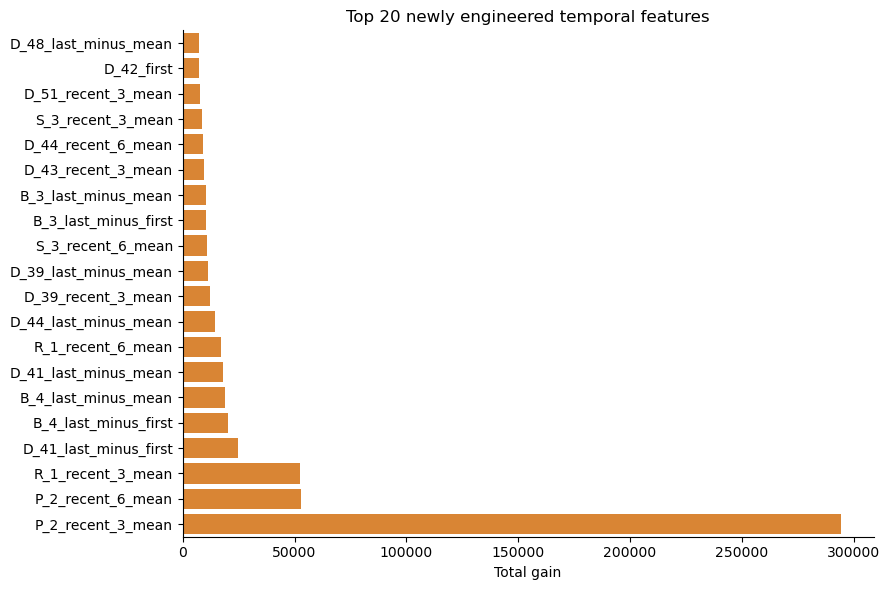

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Most influential newly engineered temporal features
new_feature_importance = v2_importance[v2_importance['feature'].isin(NEW_TEMPORAL_FEATURES)].nlargest(20, 'gain').sort_values('gain')
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=new_feature_importance, y='feature', x='gain', color='#F58518', ax=ax)
ax.set(title='Top 20 newly engineered temporal features', xlabel='Total gain', ylabel='')
sns.despine()
plt.tight_layout()
plt.show()


### 9. Save artifacts

In [ ]:
v2_model.booster_.save_model(V2_MODEL, num_iteration=v2_model.best_iteration_)
pd.DataFrame({
    'customer_ID': valid_customer_ids.to_numpy(),
    'target': y_valid.to_numpy(),
    'baseline_probability': baseline_probability.astype('float32'),
    'temporal_v2_probability': v2_probability.astype('float32'),
}).to_parquet(V2_PREDICTIONS, index=False, compression='zstd')

metrics_output = {
    'baseline': baseline_result,
    'temporal_v2': v2_result,
    'delta': {
        'roc_auc': v2_result['roc_auc'] - baseline_result['roc_auc'],
        'amex_metric': v2_result['amex_metric'] - baseline_result['amex_metric'],
        'best_iteration': v2_result['best_iteration'] - baseline_result['best_iteration'],
        'training_seconds': v2_result['training_seconds'] - baseline_result['training_seconds'],
        'feature_count': v2_result['feature_count'] - baseline_result['feature_count'],
    },
    'top25_original_variables': TOP25,
    'new_temporal_feature_count': len(NEW_TEMPORAL_FEATURES),
    'temporal_generation_seconds': temporal_generation_seconds,
}
V2_METRICS.write_text(json.dumps(metrics_output, indent=2), encoding='utf-8')

for path in [ORIGINAL_VARIABLE_IMPORTANCE, V2_DATA, V2_MODEL, V2_IMPORTANCE, V2_PREDICTIONS, V2_METRICS]:
    print(path.name, '->', path.resolve())
